In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC

from sklearn.metrics import (
confusion_matrix,
ConfusionMatrixDisplay,
classification_report,
accuracy_score,
precision_score,
recall_score,
f1_score,
roc_auc_score
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:
import pandas as pd

file_path = r"C:\Users\PATEL RUDRA\ML_Project\googleplaystore.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Number of rows and columns: (10841, 13)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [3]:
# 1. Dataset ki information
print("Dataset Information:")
df.info()

# 2. Rows aur columns
print("\nDataset Shape:")
print(df.shape)

# 3. Column names
print("\nColumn Names:")
print(df.columns.tolist())

# 4. Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# 6. Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB

Dataset Shape:
(10841, 13)

Column Names:
['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Ge

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
count,10841,10841,9367.000000,10841,10841,10841,10840,10841,10840,10841,10841,10833,10838
unique,9660,34,NaN,6002,462,22,3,93,6,120,1378,2832,33
top,ROBLOX,FAMILY,NaN,0,Varies with device,"1,000,000+",Free,0,Everyone,Tools,"August 3, 2018",Varies with device,4.1 and up
freq,9,1972,NaN,596,1695,1579,10039,10040,8714,842,326,1459,2451
mean,NaN,NaN,4.193338,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,0.537431,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,4.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,4.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,4.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Convert Rating to numeric values
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")

# Create target column
df["top_app"] = (df["Rating"] >= 4.5).astype(int)

# Remove rows where Rating is missing
df = df.dropna(subset=["Rating"])

# Display target counts
print("Target column created successfully!")

print("\nTop App Distribution:")
print(df["top_app"].value_counts())

print("\nTarget Labels:")
print("1 = App rating is 4.5 or above")
print("0 = App rating is below 4.5")

# Display first 5 rows
display(df[["App", "Rating", "top_app"]].head())

Target column created successfully!

Top App Distribution:
top_app
0    6411
1    2956
Name: count, dtype: int64

Target Labels:
1 = App rating is 4.5 or above
0 = App rating is below 4.5


,App,Rating,top_app
0,Photo Editor & Candy Camera & Grid & ScrapBook,4.1,0
1,Coloring book moana,3.9,0
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",4.7,1
3,Sketch - Draw & Paint,4.5,1
4,Pixel Draw - Number Art Coloring Book,4.3,0


In [5]:
# 1. Check the original dataset

print("Original dataset shape:", df.shape)

# 2. Remove duplicate apps

df = df.drop_duplicates(subset=["App"], keep="first")

# 3. Clean Rating

df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")

# Remove invalid ratings

df = df[df["Rating"].between(0, 5)]

# 4. Clean Reviews

df["Reviews"] = pd.to_numeric(df["Reviews"], errors="coerce")

# 5. Clean Installs

df["Installs"] = (
df["Installs"]
.astype(str)
.str.replace(",", "", regex=False)
.str.replace("+", "", regex=False)
)

df["Installs"] = pd.to_numeric(df["Installs"], errors="coerce")

# 6. Clean Size

df["Size"] = (
df["Size"]
.astype(str)
.str.replace("M", "", regex=False)
.str.replace("k", "", regex=False)
)

df["Size"] = pd.to_numeric(df["Size"], errors="coerce")

# 7. Clean Price

df["Price"] = (
df["Price"]
.astype(str)
.str.replace("$", "", regex=False)
)

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

# 8. Remove rows where target is missing

df = df.dropna(subset=["Rating"])

# 9. Check missing values

print("\nMissing values after cleaning:")
print(df.isnull().sum())

# 10. Check duplicates

print("\nDuplicate apps remaining:", df["App"].duplicated().sum())

# 11. Final dataset shape

print("\nCleaned dataset shape:", df.shape)

display(df.head())

df["top_app"] = (df["Rating"] >= 4.5).astype(int)

print("\nTarget distribution:")
print(df["top_app"].value_counts())


Original dataset shape: (9367, 14)

Missing values after cleaning:
App                  0
Category             0
Rating               0
Reviews              0
Size              1169
Installs             0
Type                 0
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          4
Android Ver          2
top_app              0
dtype: int64

Duplicate apps remaining: 0

Cleaned dataset shape: (8196, 14)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,top_app
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19.0,10000,Free,0.0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up,0
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14.0,500000,Free,0.0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up,0
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7,5000000,Free,0.0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up,1
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25.0,50000000,Free,0.0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up,1
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8,100000,Free,0.0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up,0



Target distribution:
top_app
0    5646
1    2550
Name: count, dtype: int64


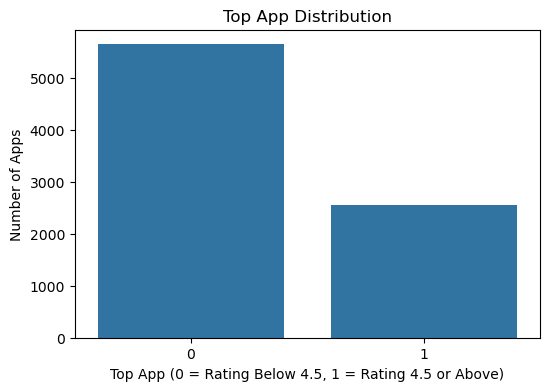

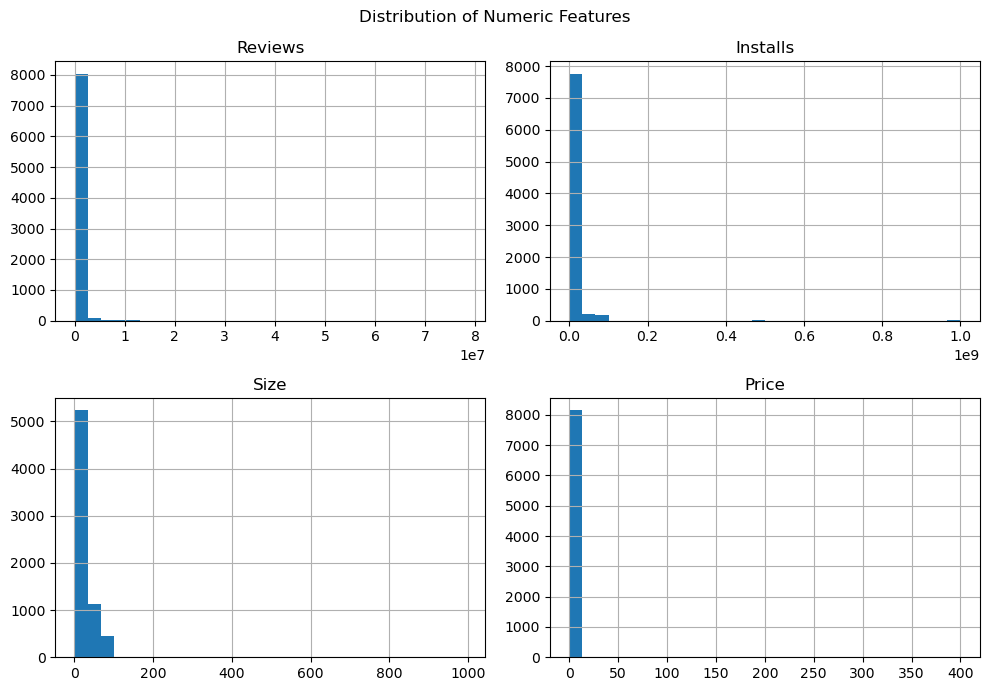

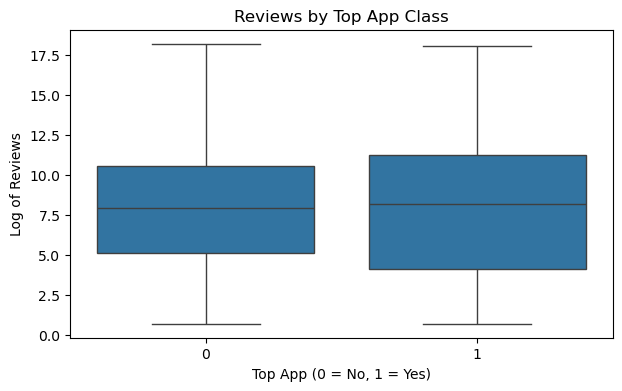

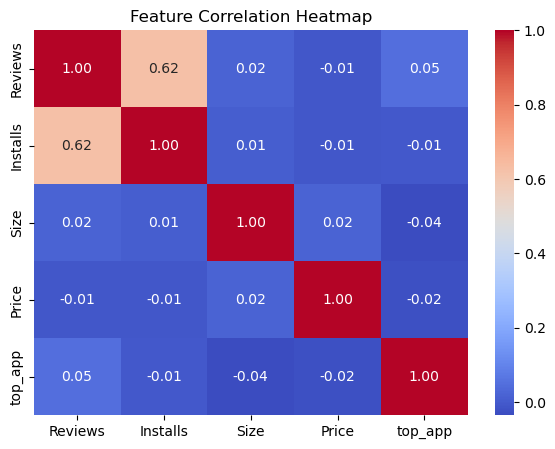

EDA completed successfully!


In [6]:
# Step 6: Exploratory Data Analysis (EDA)

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Graph 1: Top App Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="top_app")
plt.title("Top App Distribution")
plt.xlabel("Top App (0 = Rating Below 4.5, 1 = Rating 4.5 or Above)")
plt.ylabel("Number of Apps")
plt.show()

# Graph 2: Numeric Feature Distributions
numeric_cols = ["Reviews", "Installs", "Size", "Price"]

df[numeric_cols].hist(figsize=(10, 7), bins=30)
plt.suptitle("Distribution of Numeric Features")
plt.tight_layout()
plt.show()

# Graph 3: Reviews by Top App Class
df["log_reviews"] = np.log1p(df["Reviews"])

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="top_app", y="log_reviews")
plt.title("Reviews by Top App Class")
plt.xlabel("Top App (0 = No, 1 = Yes)")
plt.ylabel("Log of Reviews")
plt.show()

# Graph 4: Correlation Heatmap
corr_cols = ["Reviews", "Installs", "Size", "Price", "top_app"]

plt.figure(figsize=(7, 5))
sns.heatmap(df[corr_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

print("EDA completed successfully!")

In [7]:
# Step 7: Create Feature, Encode and Select Features

import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif

# 1. Create a new feature
df["Reviews_per_Install"] = (
    df["Reviews"] / df["Installs"].replace(0, np.nan)
)

print("New feature created: Reviews_per_Install")
print("Reason: It measures reviews relative to app installs.")

# 2. Select useful columns
features = [
    "Category",
    "Reviews",
    "Installs",
    "Size",
    "Type",
    "Price",
    "Content Rating",
    "Reviews_per_Install"
]

X = df[features].copy()
y = df["top_app"].copy()

# 3. Handle missing values
X["Reviews"] = X["Reviews"].fillna(X["Reviews"].median())
X["Installs"] = X["Installs"].fillna(X["Installs"].median())
X["Size"] = X["Size"].fillna(X["Size"].median())
X["Price"] = X["Price"].fillna(X["Price"].median())
X["Reviews_per_Install"] = X["Reviews_per_Install"].fillna(0)

X["Category"] = X["Category"].fillna("Unknown")
X["Type"] = X["Type"].fillna("Unknown")
X["Content Rating"] = X["Content Rating"].fillna("Unknown")

# 4. Encode target using LabelEncoder
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# 5. One-hot encode text columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("\nShape after encoding:", X.shape)

# 6. Select up to 15 best features
k = min(15, X.shape[1])

selector = SelectKBest(score_func=f_classif, k=k)
X_selected_array = selector.fit_transform(X, y)

selected_features = X.columns[selector.get_support()].tolist()

X_selected = pd.DataFrame(
    X_selected_array,
    columns=selected_features,
    index=X.index
)

print("\nSelected Features:")
for feature in selected_features:
    print(feature)

print("\nNumber of selected features:", len(selected_features))
print("Final X shape:", X_selected.shape)
print("Final y shape:", y.shape)

print("\nStep 7 completed successfully!")

New feature created: Reviews_per_Install
Reason: It measures reviews relative to app installs.

Shape after encoding: (8196, 43)

Selected Features:
Reviews
Size
Reviews_per_Install
Category_BOOKS_AND_REFERENCE
Category_COMMUNICATION
Category_DATING
Category_ENTERTAINMENT
Category_EVENTS
Category_HEALTH_AND_FITNESS
Category_MAPS_AND_NAVIGATION
Category_PERSONALIZATION
Category_TOOLS
Category_TRAVEL_AND_LOCAL
Type_Paid
Content Rating_Mature 17+

Number of selected features: 15
Final X shape: (8196, 15)
Final y shape: (8196,)

Step 7 completed successfully!


In [8]:
# Step 8: Train-Test Split and Feature Scaling

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X_selected,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset split successfully!")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

# Scale the features for SVM
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling completed successfully!")

Dataset split successfully!
Training features: (6556, 15)
Testing features: (1640, 15)
Training target: (6556,)
Testing target: (1640,)

Feature scaling completed successfully!


In [10]:
# Step 9: Train SVM Model

from sklearn.svm import SVC

# Create SVM model
svm_model = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

# Train the model
svm_model.fit(X_train_scaled, y_train)

print("SVM model trained successfully!")

# Make predictions
y_pred = svm_model.predict(X_test_scaled)

print("Predictions completed!")
print("\nFirst 10 actual values:", y_test[:10])
print("First 10 predicted values:", y_pred[:10])

SVM model trained successfully!
Predictions completed!

First 10 actual values: [0 0 0 0 0 0 1 0 0 1]
First 10 predicted values: [0 0 0 0 0 0 0 0 0 0]


In [11]:
# Step 10: Model Evaluation

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Specificity
tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

# ROC-AUC
y_prob = svm_model.predict_proba(X_test_scaled)[:, 1]
roc_auc = roc_auc_score(y_test, y_prob)

# Print results
print("\nModel Evaluation Results")
print("------------------------")
print(f"Accuracy:    {accuracy:.4f}")
print(f"Precision:   {precision:.4f}")
print(f"Recall:      {recall:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"ROC-AUC:     {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[1085   45]
 [ 413   97]]

Model Evaluation Results
------------------------
Accuracy:    0.7207
Precision:   0.6831
Recall:      0.1902
F1-Score:    0.2975
Specificity: 0.9602
ROC-AUC:     0.7049

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.96      0.83      1130
           1       0.68      0.19      0.30       510

    accuracy                           0.72      1640
   macro avg       0.70      0.58      0.56      1640
weighted avg       0.71      0.72      0.66      1640



SVM Comparison Table:


,Kernel,C,Accuracy,Precision,Recall,F1,AUC
1,rbf,10,0.725610,0.685185,0.217647,0.330357,0.702186
2,linear,1,0.715854,0.629412,0.209804,0.314706,0.701261
0,rbf,1,0.720732,0.683099,0.190196,0.297546,0.704893


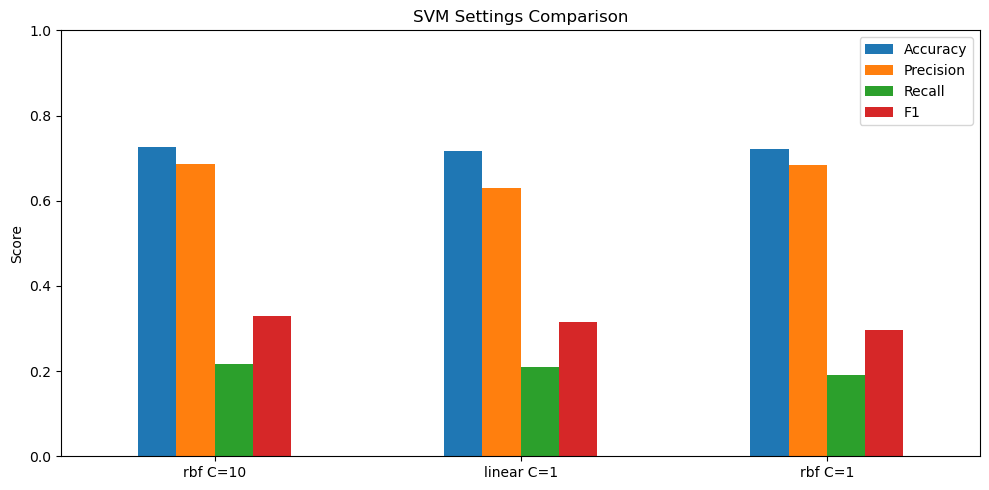


Best SVM Setting:
Kernel: rbf
C: 10
Best F1: 0.3304
Best AUC: 0.7022
Final model trained successfully!

Final Confusion Matrix:
[[1079   51]
 [ 399  111]]


In [13]:
# Step 11: Compare SVM Settings

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd
import matplotlib.pyplot as plt

# Try different SVM settings
settings = [
    {"kernel": "rbf", "C": 1},
    {"kernel": "rbf", "C": 10},
    {"kernel": "linear", "C": 1}
]

results = []

for setting in settings:
    model = SVC(
        kernel=setting["kernel"],
        C=setting["C"],
        probability=True,
        random_state=42
    )

    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)
    probabilities = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        "Kernel": setting["kernel"],
        "C": setting["C"],
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("F1", ascending=False)

print("SVM Comparison Table:")
display(results_df)

# Plot comparison chart
results_df.set_index(
    results_df["Kernel"] + " C=" + results_df["C"].astype(str)
)[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("SVM Settings Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Select best setting using F1
best_setting = results_df.iloc[0]

print("\nBest SVM Setting:")
print("Kernel:", best_setting["Kernel"])
print("C:", best_setting["C"])
print("Best F1:", round(best_setting["F1"], 4))
print("Best AUC:", round(best_setting["AUC"], 4))

# Create final model using the best settings

final_model = SVC(
    kernel=best_setting["Kernel"],
    C=float(best_setting["C"]),
    probability=True,
    random_state=42
)

final_model.fit(X_train_scaled, y_train)

final_predictions = final_model.predict(X_test_scaled)

print("Final model trained successfully!")
print("\nFinal Confusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

In [14]:
# Step 12: Predict 3 New Inputs

# Select 3 rows from the processed feature dataset
new_apps = X_selected.iloc[:3].copy()

# Scale using the same scaler from Step 8
new_apps_scaled = scaler.transform(new_apps)

# Predict using the final model
new_predictions = final_model.predict(new_apps_scaled)

print("Predictions for 3 Apps:\n")

for i, prediction in enumerate(new_predictions):
    label = "Top App (Rating >= 4.5)" if prediction == 1 else "Not Top App (Rating < 4.5)"
    print(f"App {i+1}: {label}")

Predictions for 3 Apps:

App 1: Not Top App (Rating < 4.5)
App 2: Not Top App (Rating < 4.5)
App 3: Not Top App (Rating < 4.5)
